# Tweet Sentiment Analysis using Deep Learning
**Models:** SimpleRNN, LSTM, GRU, BiLSTM, BiGRU
**Dataset:** Sentiment140 (target: `0` = negative, `4` = positive, text = column index 5)
**Split:** 70% train / 10% validation / 20% test (stratified)
**Metrics:** Accuracy, Precision, Recall, F1, ROC-AUC, MCC, Classification Report, Confusion Matrix, ROC curves, training curves

## 1. Imports

In [3]:
import os, re, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, classification_report,
                             confusion_matrix, roc_curve)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Embedding, SimpleRNN, LSTM, GRU, Bidirectional,
                                     Dense, Dropout, SpatialDropout1D)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: []


## 2. Configuration
- `SAMPLE_SIZE`: the full dataset has 1.6M tweets. Training 5 models on all of them is slow, so a balanced sample is used by default. Set to `None` to use everything.
- Change `DATA_PATH` to where your CSV is stored (e.g. `/content/training.1600000.processed.noemoticon.csv` in Colab).

In [4]:
DATA_PATH   = "tweet_sentiment.csv"
SAMPLE_SIZE = 200000      # set to None to use the full 1.6M tweets
MAX_WORDS   = 20000       # vocabulary size
MAX_LEN     = 40          # max tokens per tweet
EMBED_DIM   = 128
UNITS       = 64
BATCH_SIZE  = 256
EPOCHS      = 10
OOV_TOKEN   = "<OOV>"


## 3. Load the dataset

In [5]:
# The file has no header: 0=target, 1=id, 2=date, 3=flag, 4=user, 5=text
df = pd.read_csv(DATA_PATH, encoding="latin-1", header=None, usecols=[0, 5])
df.columns = ["target", "text"]

print("Shape:", df.shape)
print(df["target"].value_counts())
df.head()

Shape: (1600000, 2)
target
0    800000
4    800000
Name: count, dtype: int64


,target,text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,is upset that he can't update his Facebook by ...
2,0,@Kenichan I dived many times for the ball. Man...
3,0,my whole body feels itchy and like its on fire
4,0,"@nationwideclass no, it's not behaving at all...."


Final dataset size: 200000


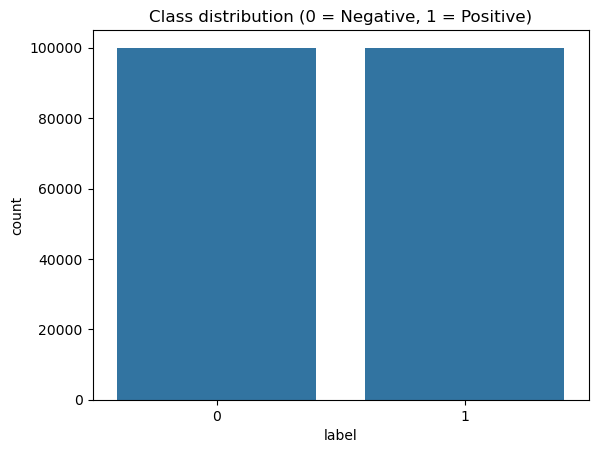

In [6]:
# Map labels: 0 -> 0 (negative), 4 -> 1 (positive)
df["label"] = df["target"].map({0: 0, 4: 1})
df = df.dropna(subset=["label", "text"]).drop_duplicates(subset="text").reset_index(drop=True)
df["label"] = df["label"].astype(int)

# Optional balanced sampling
if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df):
    per_class = SAMPLE_SIZE // 2
    df = (df.groupby("label", group_keys=False)
            .apply(lambda g: g.sample(min(per_class, len(g)), random_state=SEED))
            .sample(frac=1, random_state=SEED).reset_index(drop=True))

print("Final dataset size:", len(df))
sns.countplot(x="label", data=df)
plt.title("Class distribution (0 = Negative, 1 = Positive)")
plt.show()

## 4. Text preprocessing

In [7]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)   # URLs
    t = re.sub(r"@\w+", " ", t)               # mentions
    t = t.replace("#", "")                    # hashtag symbol
    t = re.sub(r"&\w+;", " ", t)              # html entities like &amp;
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)      # sooooo -> soo
    t = re.sub(r"[^a-z\s']", " ", t)          # keep letters only
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
df[["text", "clean_text", "label"]].head(10)

,text,clean_text,label
0,priecÄ«gs albums svÄtdienai! The Vampire Week...,priec gs albums sv tdienai the vampire weekend...,1
1,@msdivineknight Don't know...When I went to hi...,don't know when i went to his twitter page it ...,0
2,@crobwin HellOOooo Rob Ya Twit.. heh,helloo rob ya twit heh,1
3,Times like this when I hate being sick. I need...,times like this when i hate being sick i need ...,0
4,Killing time through pointlism/stippling.,killing time through pointlism stippling,0
5,Holy crap! Did they actually add a &quot;disli...,holy crap did they actually add a dislike butt...,0
6,I ran into John SSN again in the bus today!,i ran into john ssn again in the bus today,1
7,"@TimmyGrunt ok, following you now! Sorry about...",ok following you now sorry about that,1
8,"Just Camee Home From The Hospital , Feelinq Be...",just camee home from the hospital feelinq better,1
9,"ugh, first day back to school RIP, Columbine ...",ugh first day back to school rip columbine vic...,0


## 5. Train / Validation / Test split (70% / 10% / 20%)

In [8]:
X = df["clean_text"].values
y = df["label"].values

# 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
# 10% of the total = 0.10 / 0.80 = 12.5% of the remaining data
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=SEED)

total = len(X)
print(f"Train: {len(X_train)} ({len(X_train)/total:.1%})")
print(f"Val  : {len(X_val)} ({len(X_val)/total:.1%})")
print(f"Test : {len(X_test)} ({len(X_test)/total:.1%})")

Train: 139692 (70.0%)
Val  : 19956 (10.0%)
Test : 39913 (20.0%)


## 6. Tokenization & padding
The tokenizer is fitted on the **training set only** to avoid data leakage.

In [9]:
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train)

def to_seq(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts),
                         maxlen=MAX_LEN, padding="post", truncating="post")

X_train_seq, X_val_seq, X_test_seq = to_seq(X_train), to_seq(X_val), to_seq(X_test)
vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)
print("Vocab size:", vocab_size)
print("Train shape:", X_train_seq.shape, "| Val shape:", X_val_seq.shape, "| Test shape:", X_test_seq.shape)

Vocab size: 20000
Train shape: (139692, 40) | Val shape: (19956, 40) | Test shape: (39913, 40)


## 7. Model builder

In [10]:
def build_model(model_type):
    model = Sequential(name=model_type)
    model.add(Embedding(vocab_size, EMBED_DIM))
    model.add(SpatialDropout1D(0.2))

    if model_type == "RNN":
        model.add(SimpleRNN(UNITS))
    elif model_type == "LSTM":
        model.add(LSTM(UNITS))
    elif model_type == "GRU":
        model.add(GRU(UNITS))
    elif model_type == "BiLSTM":
        model.add(Bidirectional(LSTM(UNITS)))
    elif model_type == "BiGRU":
        model.add(Bidirectional(GRU(UNITS)))
    else:
        raise ValueError("Unknown model type")

    model.add(Dropout(0.4))
    model.add(Dense(32, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation="sigmoid"))

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    model.build(input_shape=(None, MAX_LEN))
    return model

build_model("LSTM").summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 40, 128)             │       2,560,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d (SpatialDropout1D) │ (None, 40, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,611,521 (9.96 MB)

 Trainable params: 2,611,521 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train all models

In [11]:
MODEL_NAMES = ["RNN", "LSTM", "GRU", "BiLSTM", "BiGRU"]
histories, trained_models, train_times = {}, {}, {}

for name in MODEL_NAMES:
    print("\n" + "=" * 70 + f"\nTraining {name}\n" + "=" * 70)
    model = build_model(name)
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
    ]
    start = time.time()
    hist = model.fit(X_train_seq, y_train,
                     validation_data=(X_val_seq, y_val),
                     epochs=EPOCHS, batch_size=BATCH_SIZE,
                     callbacks=callbacks, verbose=1)
    train_times[name] = time.time() - start
    histories[name], trained_models[name] = hist.history, model
    print(f"{name} training time: {train_times[name]/60:.2f} min")


Training RNN
Epoch 1/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - accuracy: 0.7204 - loss: 0.5559 - val_accuracy: 0.7789 - val_loss: 0.4833 - learning_rate: 0.0010
Epoch 2/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - accuracy: 0.8046 - loss: 0.4449 - val_accuracy: 0.7821 - val_loss: 0.4783 - learning_rate: 0.0010
Epoch 3/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8309 - loss: 0.4006
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
546/546 ━━━━━━━━━━━━━━━━━━━━ 19s 34ms/step - accuracy: 0.8364 - loss: 0.3895 - val_accuracy: 0.7770 - val_loss: 0.5033 - learning_rate: 0.0010
Epoch 4/10
545/546 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8621 - loss: 0.3403
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
546/546 ━━━━━━━━━━━━━━━━━━━━ 18s 33ms/step - accuracy: 0.8697 - loss: 0.3253 - val_accuracy: 0.7594 - val_loss: 0.5322 - learning_rate: 5.0000e-04
Epoch 5/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accurac

## 9. Training curves (accuracy & loss)

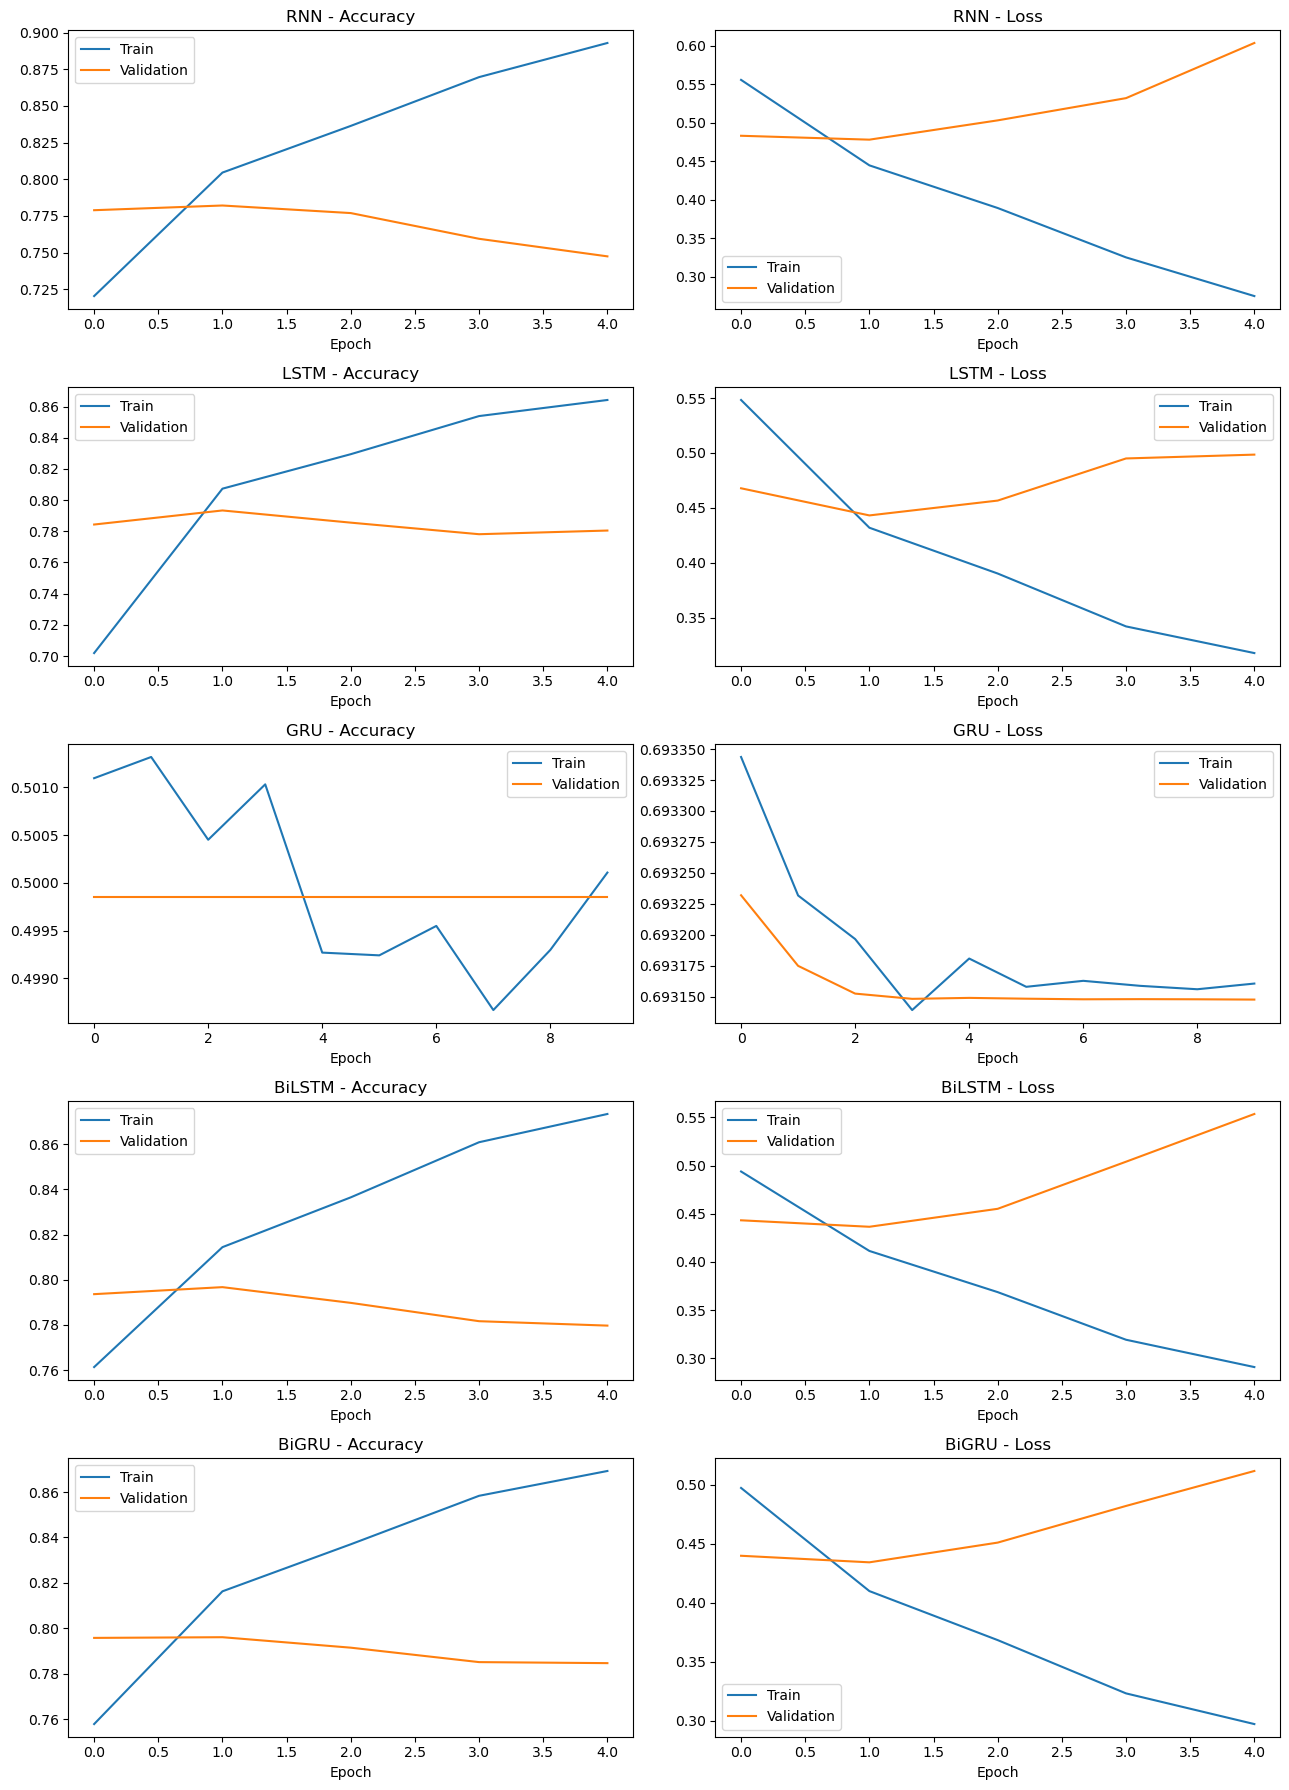

In [12]:
fig, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(13, 3.6 * len(MODEL_NAMES)))
for i, name in enumerate(MODEL_NAMES):
    h = histories[name]
    axes[i, 0].plot(h["accuracy"], label="Train"); axes[i, 0].plot(h["val_accuracy"], label="Validation")
    axes[i, 0].set_title(f"{name} - Accuracy"); axes[i, 0].set_xlabel("Epoch"); axes[i, 0].legend()
    axes[i, 1].plot(h["loss"], label="Train"); axes[i, 1].plot(h["val_loss"], label="Validation")
    axes[i, 1].set_title(f"{name} - Loss"); axes[i, 1].set_xlabel("Epoch"); axes[i, 1].legend()
plt.tight_layout(); plt.show()

## 10. Evaluation on the test set

In [13]:
results, preds, probs = [], {}, {}
class_names = ["Negative", "Positive"]

for name in MODEL_NAMES:
    model = trained_models[name]
    y_prob = model.predict(X_test_seq, batch_size=1024, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    probs[name], preds[name] = y_prob, y_pred
    test_loss, _ = model.evaluate(X_test_seq, y_test, batch_size=1024, verbose=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Test Loss": test_loss,
        "Params": model.count_params(),
        "Train Time (min)": train_times[name] / 60,
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC,Test Loss,Params,Train Time (min)
Model,,,,,,,,,
RNN,0.7844,0.7766,0.7982,0.7873,0.8630,0.5689,0.4732,2574465,1.5103
LSTM,0.7984,0.7889,0.8146,0.8015,0.8797,0.5970,0.4402,2611521,2.8191
GRU,0.4999,0.4999,1.0000,0.6666,0.5001,0.0071,0.6931,2599361,5.1157
BiLSTM,0.7992,0.7873,0.8199,0.8033,0.8813,0.5990,0.4347,2662977,2.9881
BiGRU,0.7981,0.7914,0.8094,0.8003,0.8811,0.5963,0.4334,2638657,2.8986


## 11. Classification report for each model

In [14]:
for name in MODEL_NAMES:
    print("=" * 60)
    print(f"Classification Report - {name}")
    print("=" * 60)
    print(classification_report(y_test, preds[name], target_names=class_names, digits=4))

Classification Report - RNN
              precision    recall  f1-score   support

    Negative     0.7925    0.7705    0.7814     19962
    Positive     0.7766    0.7982    0.7873     19951

    accuracy                         0.7844     39913
   macro avg     0.7846    0.7844    0.7843     39913
weighted avg     0.7846    0.7844    0.7843     39913

Classification Report - LSTM
              precision    recall  f1-score   support

    Negative     0.8085    0.7821    0.7951     19962
    Positive     0.7889    0.8146    0.8015     19951

    accuracy                         0.7984     39913
   macro avg     0.7987    0.7984    0.7983     39913
weighted avg     0.7987    0.7984    0.7983     39913

Classification Report - GRU
              precision    recall  f1-score   support

    Negative     1.0000    0.0001    0.0002     19962
    Positive     0.4999    1.0000    0.6666     19951

    accuracy                         0.4999     39913
   macro avg     0.7499    0.5001    0.3334

## 12. Confusion matrices

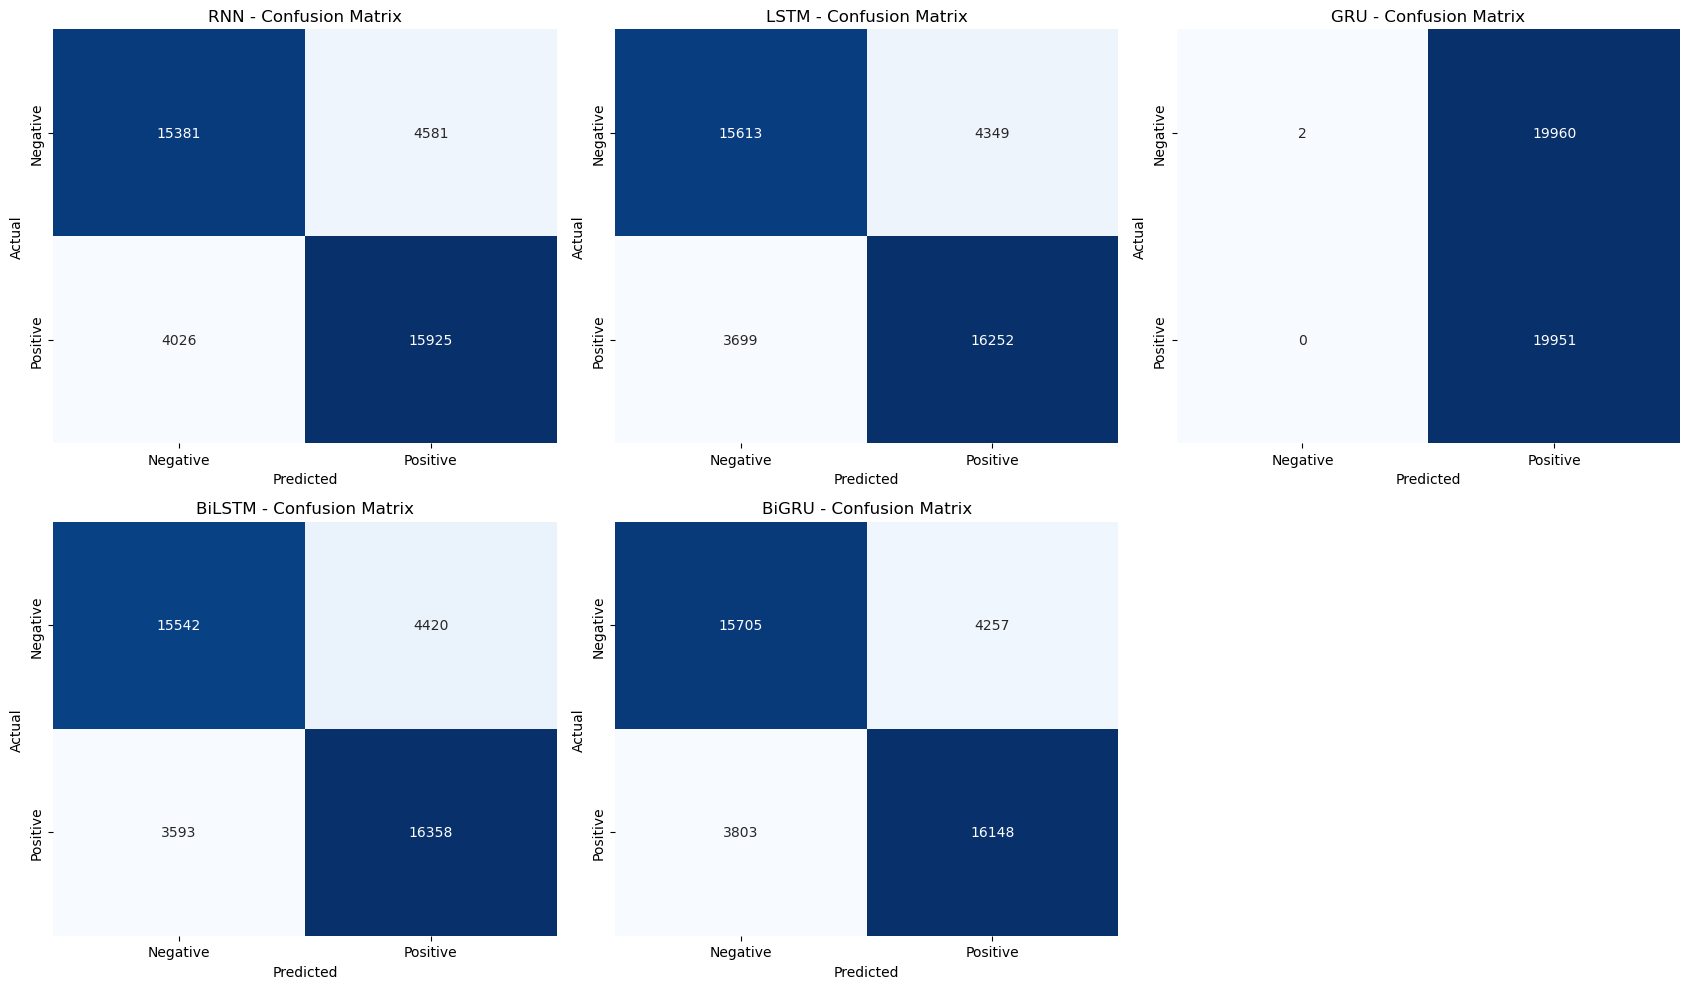

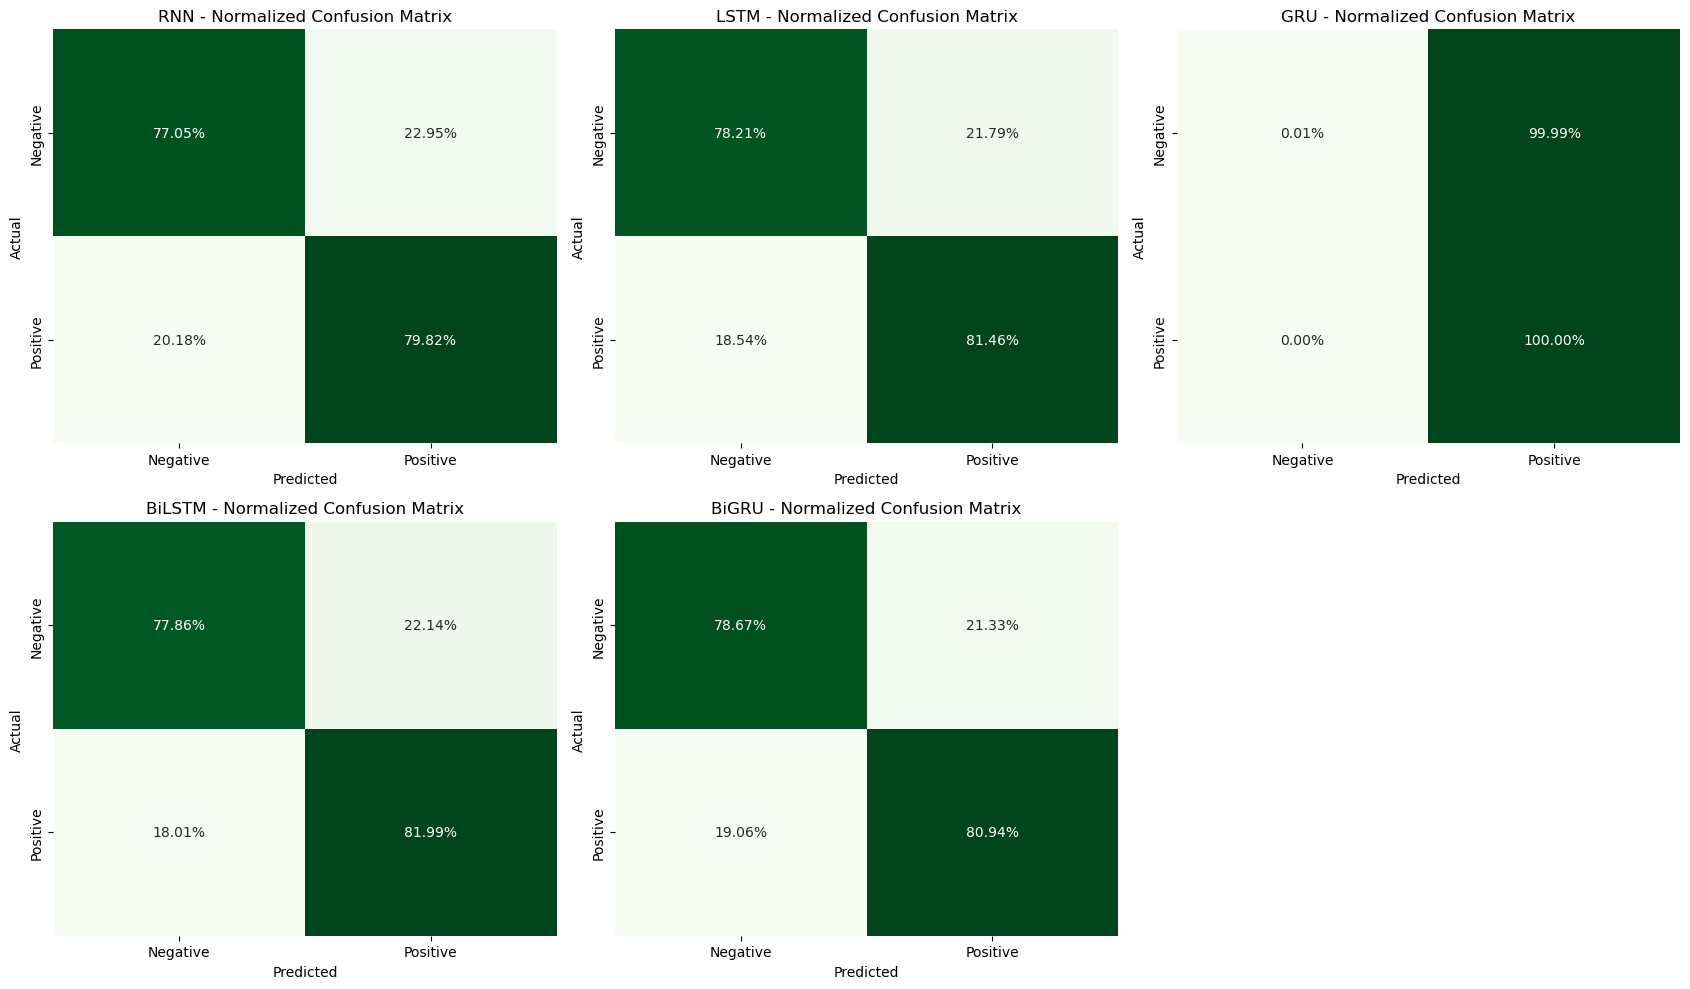

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()
for i, name in enumerate(MODEL_NAMES):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
                xticklabels=class_names, yticklabels=class_names)
    axes[i].set_title(f"{name} - Confusion Matrix")
    axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("Actual")
axes[-1].axis("off")
plt.tight_layout(); plt.show()

# Normalized version
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()
for i, name in enumerate(MODEL_NAMES):
    cm = confusion_matrix(y_test, preds[name], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2%", cmap="Greens", cbar=False, ax=axes[i],
                xticklabels=class_names, yticklabels=class_names)
    axes[i].set_title(f"{name} - Normalized Confusion Matrix")
    axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("Actual")
axes[-1].axis("off")
plt.tight_layout(); plt.show()

## 13. ROC curves

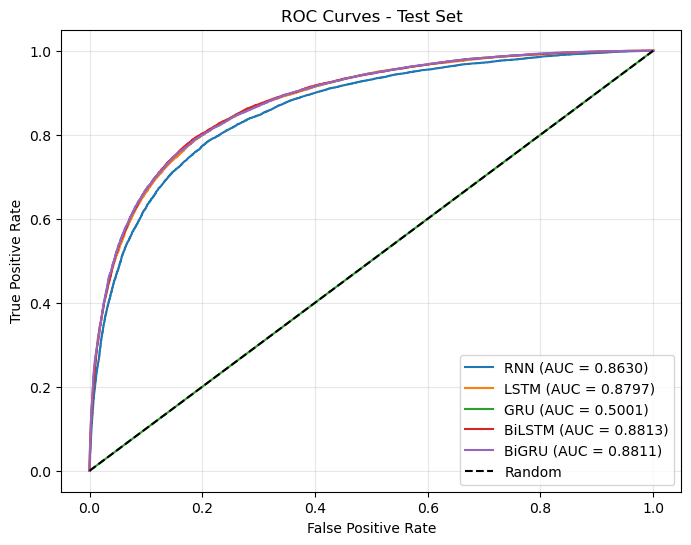

In [16]:
plt.figure(figsize=(8, 6))
for name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs[name]):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Test Set"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()

## 14. Model comparison

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC,Test Loss,Params,Train Time (min)
Model,,,,,,,,,
RNN,0.7844,0.7766,0.7982,0.7873,0.8630,0.5689,0.4732,2574465,1.5103
LSTM,0.7984,0.7889,0.8146,0.8015,0.8797,0.5970,0.4402,2611521,2.8191
GRU,0.4999,0.4999,1.0000,0.6666,0.5001,0.0071,0.6931,2599361,5.1157
BiLSTM,0.7992,0.7873,0.8199,0.8033,0.8813,0.5990,0.4347,2662977,2.9881
BiGRU,0.7981,0.7914,0.8094,0.8003,0.8811,0.5963,0.4334,2638657,2.8986


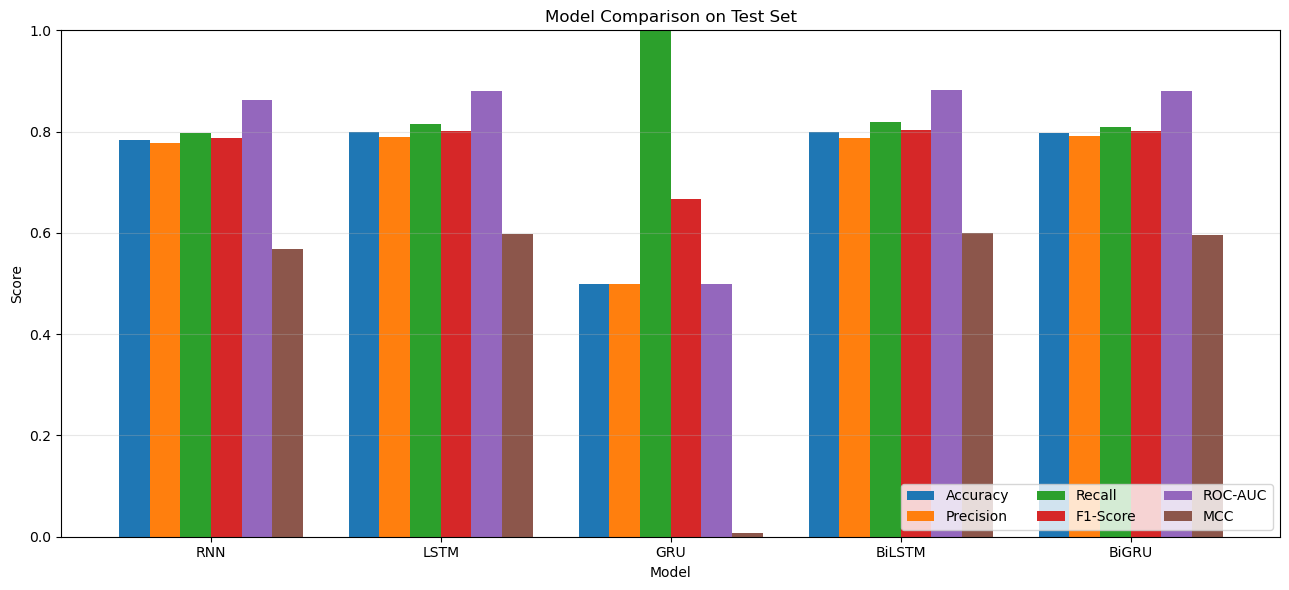

Best model by F1-score: BiLSTM  (Accuracy=0.7992, F1=0.8033)


In [17]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "MCC"]
display(results_df.round(4))

ax = results_df[metric_cols].plot(kind="bar", figsize=(13, 6), width=0.8)
plt.title("Model Comparison on Test Set")
plt.ylabel("Score"); plt.xticks(rotation=0)
plt.ylim(max(0, results_df[metric_cols].values.min() - 0.05), 1.0)
plt.legend(loc="lower right", ncol=3); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

best = results_df["F1-Score"].idxmax()
print(f"Best model by F1-score: {best}  "
      f"(Accuracy={results_df.loc[best, 'Accuracy']:.4f}, F1={results_df.loc[best, 'F1-Score']:.4f})")

## 15. Save results and models

In [18]:
os.makedirs("outputs", exist_ok=True)
results_df.round(4).to_csv("outputs/model_comparison_results.csv")

for name, model in trained_models.items():
    model.save(f"outputs/{name}_sentiment.keras")

import pickle
with open("outputs/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("Saved results, models and tokenizer to ./outputs")

Saved results, models and tokenizer to ./outputs


## 16. Predict on custom tweets

In [19]:
def predict_sentiment(texts, model_name=None):
    model = trained_models[model_name or best]
    seq = to_seq([clean_text(t) for t in texts])
    p = model.predict(seq, verbose=0).ravel()
    return pd.DataFrame({"tweet": texts,
                         "sentiment": np.where(p >= 0.5, "Positive", "Negative"),
                         "confidence": np.where(p >= 0.5, p, 1 - p).round(4)})

predict_sentiment([
    "I love this phone, the battery life is amazing!",
    "worst service ever, I am so disappointed",
    "just had a great day at the beach with friends",
    "I hate waiting in traffic, so annoying",
])

,tweet,sentiment,confidence
0,"I love this phone, the battery life is amazing!",Positive,0.9214
1,"worst service ever, I am so disappointed",Negative,0.9973
2,just had a great day at the beach with friends,Positive,0.9606
3,"I hate waiting in traffic, so annoying",Negative,0.9717
